# DICE FEST 2026 - Urban Energy Transition

Prediksi lima target energi menggunakan data bangunan, iklim, dan sosiodemografi. Seluruh fitur berasal dari data kompetisi. 

**Objektif:** Mengurangi NRMSE dari 5 target tersebut. 

### 1. Import library dan konfigurasi

Menetapkan pustaka, seed, lima target, dan metrik resmi kompetisi.

In [27]:
import copy
import gc
import itertools
import math
import random
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import xgboost
from scipy.optimize import nnls
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

SEED = 42
N_SPLITS = 5
INNER_TE_SPLITS = 5
ID_COL = "id"
REGION_COL = "zone_region_id"
SUBZONE_COL = "subzone_id"
AREA_COL = "bld_dim_06"
SUBMISSION_PATH = "submission_dicefest_gabungan.csv"
HAS_TORCH = True

T_GAS = "target_macro_gas_kwh"
T_ELEC = "target_macro_elec_kwh"
T_EUI = "target_eui_gas_kwh_per_sqm"
T_CLEAN = "target_clean_building_ratio"
T_HEAT = "target_electric_heating_adoption"
TARGETS = [T_GAS, T_ELEC, T_EUI, T_CLEAN, T_HEAT]
SIGMAS = {T_GAS: 151750.04, T_ELEC: 41725.37, T_EUI: 40.65, T_CLEAN: 12.49, T_HEAT: 7.18}
UPPER = {T_GAS: np.inf, T_ELEC: np.inf, T_EUI: np.inf, T_CLEAN: 100.0, T_HEAT: 100.0}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def resolve_data_file(filename):
    path = Path(filename)
    if path.exists():
        return str(path)
    for root in [Path("/kaggle/input"), Path("/mnt/data")]:
        if root.exists():
            matches = sorted(root.rglob(filename))
            if matches:
                return str(matches[0])
    raise FileNotFoundError(f"File {filename} tidak ditemukan.")

TRAIN_PATH = resolve_data_file("train.csv")
TEST_PATH = resolve_data_file("test.csv")
HAS_GPU = shutil.which("nvidia-smi") is not None
print("XGBoost:", xgboost.__version__, "| CUDA:", torch.cuda.is_available())


XGBoost: 3.4.1 | CUDA: True


### 2. Memuat data dan metrik evaluasi

Membaca train dan test, memeriksa kolom penting, lalu menyiapkan random 5-fold untuk OOF model utama.

In [28]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
required = [ID_COL, REGION_COL, SUBZONE_COL, AREA_COL, *TARGETS]
missing_train = [c for c in required if c not in train.columns]
missing_test = [c for c in [ID_COL, REGION_COL, SUBZONE_COL, AREA_COL] if c not in test.columns]
if missing_train or missing_test:
    raise ValueError(f"Missing columns | train={missing_train} | test={missing_test}")
if train[ID_COL].duplicated().any() or test[ID_COL].duplicated().any():
    print("Warning: duplicate IDs found; verify split construction.")

print("train:", train.shape, "| test:", test.shape)
print("region overlap:", round(test[REGION_COL].isin(train[REGION_COL]).mean(), 4))
print("subzone overlap:", round(test[SUBZONE_COL].isin(train[SUBZONE_COL]).mean(), 4))

folds = list(KFold(N_SPLITS, shuffle=True, random_state=SEED).split(train))

def nrmse_one(target, y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)) / SIGMAS[target])

def clipped(target, pred):
    return np.clip(np.asarray(pred, dtype=float), 0, UPPER[target])

BASELINE = {t: nrmse_one(t, train[t], np.full(len(train), train[t].mean())) for t in TARGETS}
print("mean-predictor NRMSE:", {k: round(v, 3) for k, v in BASELINE.items()})


train: (429303, 209) | test: (183987, 204)
region overlap: 1.0
subzone overlap: 0.9186
mean-predictor NRMSE: {'target_macro_gas_kwh': 1.0, 'target_macro_elec_kwh': 1.0, 'target_eui_gas_kwh_per_sqm': 1.0, 'target_clean_building_ratio': 1.0, 'target_electric_heating_adoption': 1.001}


### 3. Pemeriksaan kualitas data

Nilai kosong dan kolom konstan diperiksa sebelum fitur dibentuk. Model pohon menangani NaN secara langsung; MLP menggunakan median dari fold latih.

In [29]:
missing_train = train.isna().sum()
missing_test = test.isna().sum()
display(pd.DataFrame({"train": missing_train, "test": missing_test}).query("train > 0 or test > 0"))
print("Missing train:", missing_train.sum(), "| missing test:", missing_test.sum())
print("Pola missing pada bld_dim_04 dan bld_dim_07:")
display(pd.crosstab(train["bld_dim_04"].isna(), train["bld_dim_07"].isna()))
assert train[TARGETS].notna().all().all()


,train,test
bld_dim_04,695,336.0
bld_dim_07,695,336.0


Missing train: 1390 | missing test: 672
Pola missing pada bld_dim_04 dan bld_dim_07:


bld_dim_07,False,True
bld_dim_04,,
False,428608,0
True,0,695


### 4. Distribusi target

Distribusi dan nilai batas membantu melihat target yang tidak simetris, termasuk clean ratio 100% dan heating 0%.

In [30]:
TARGET_COLS = TARGETS
summary = train[TARGET_COLS].agg(["mean", "median", "std", "skew", "min", "max"]).T
display(summary.round(3))
print("Clean = 100:", round((train[T_CLEAN] == 100).mean() * 100, 2), "%")
print("Heating = 0:", round((train[T_HEAT] == 0).mean() * 100, 2), "%")


,mean,median,std,skew,min,max
target_macro_gas_kwh,230372.428,193549.477,151750.038,1.218,4324.152,999764.899
target_macro_elec_kwh,63755.899,53838.933,41725.369,1.227,2967.900,396491.975
target_eui_gas_kwh_per_sqm,139.063,134.848,40.652,1.298,5.121,648.107
target_clean_building_ratio,90.763,96.300,12.491,-1.569,8.330,100.000
target_electric_heating_adoption,5.380,3.101,7.185,3.403,0.000,93.237


Clean = 100: 46.12 %
Heating = 0: 7.89 %


### 4.1 Visualisasi distribusi

Lima histogram menunjukkan skala dan bentuk masing-masing target.

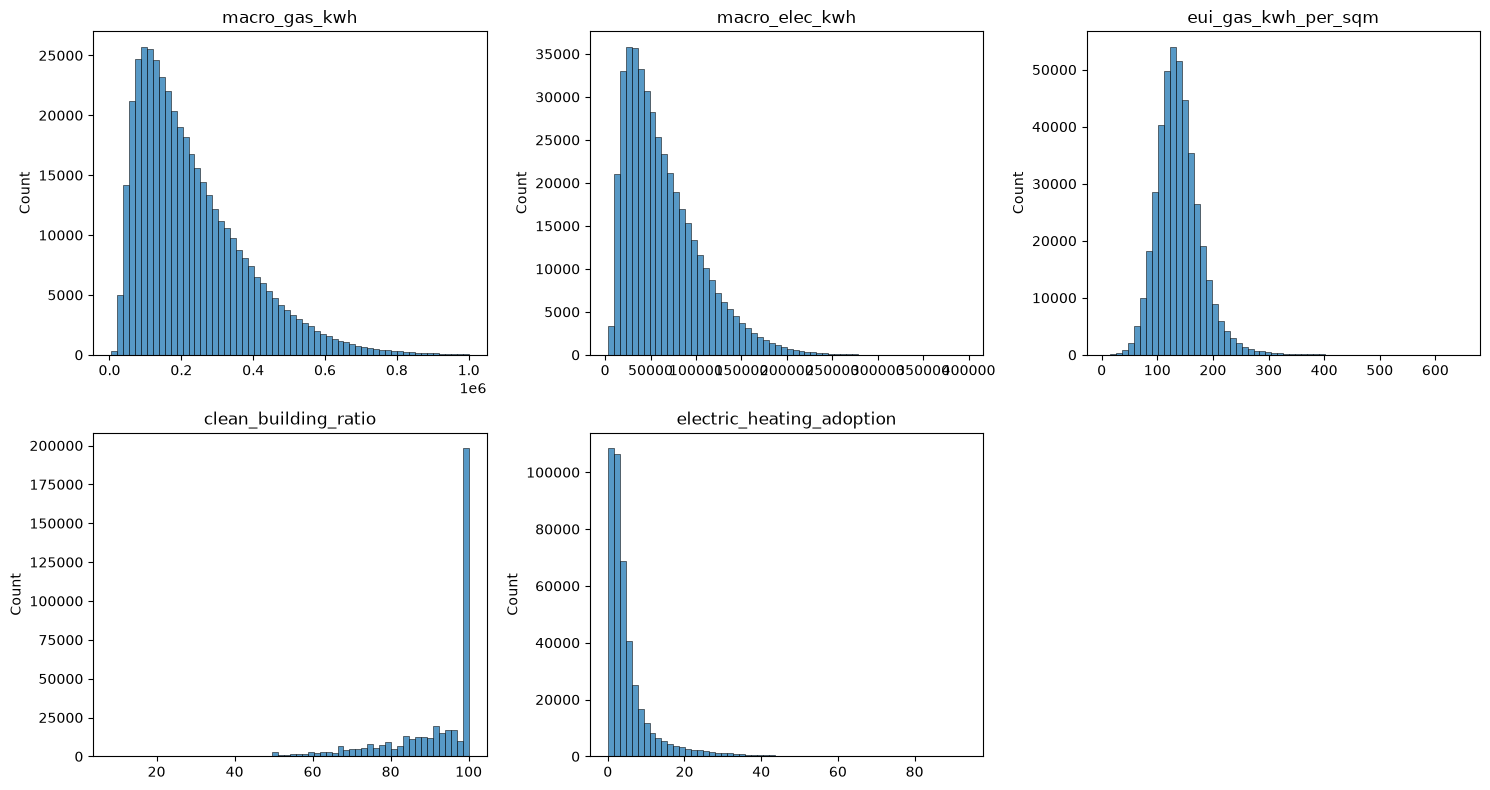

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, TARGET_COLS):
    sns.histplot(train[col], bins=60, ax=ax)
    ax.set_title(col.replace('target_', ''))
    ax.set_xlabel('')

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()


### 5. Variasi antarkawasan

Pengelompokan wilayah diperiksa karena observasi pada region yang sama dapat memiliki karakteristik serupa.

In [32]:
region_counts = train[REGION_COL].value_counts()
display(region_counts.describe(percentiles=[0.05, 0.50, 0.95]).round(1))
region_mean = train.groupby(REGION_COL)[TARGETS].transform("mean")
y_region = train[TARGETS]
eta_squared = ((region_mean - y_region.mean()) ** 2).sum() / ((y_region - y_region.mean()) ** 2).sum()
display(eta_squared.sort_values(ascending=False).to_frame("eta_squared").round(4))


count     330.0
mean     1300.9
std       923.7
min         4.0
5%        418.2
50%      1021.5
95%      3019.4
max      7072.0
Name: count, dtype: float64

,eta_squared
target_clean_building_ratio,0.1734
target_eui_gas_kwh_per_sqm,0.1251
target_electric_heating_adoption,0.0658
target_macro_gas_kwh,0.0565
target_macro_elec_kwh,0.0344


### 5.1 Pola target pada region terbesar

Rata-rata target dinormalisasi agar kelima satuan dapat dibandingkan.

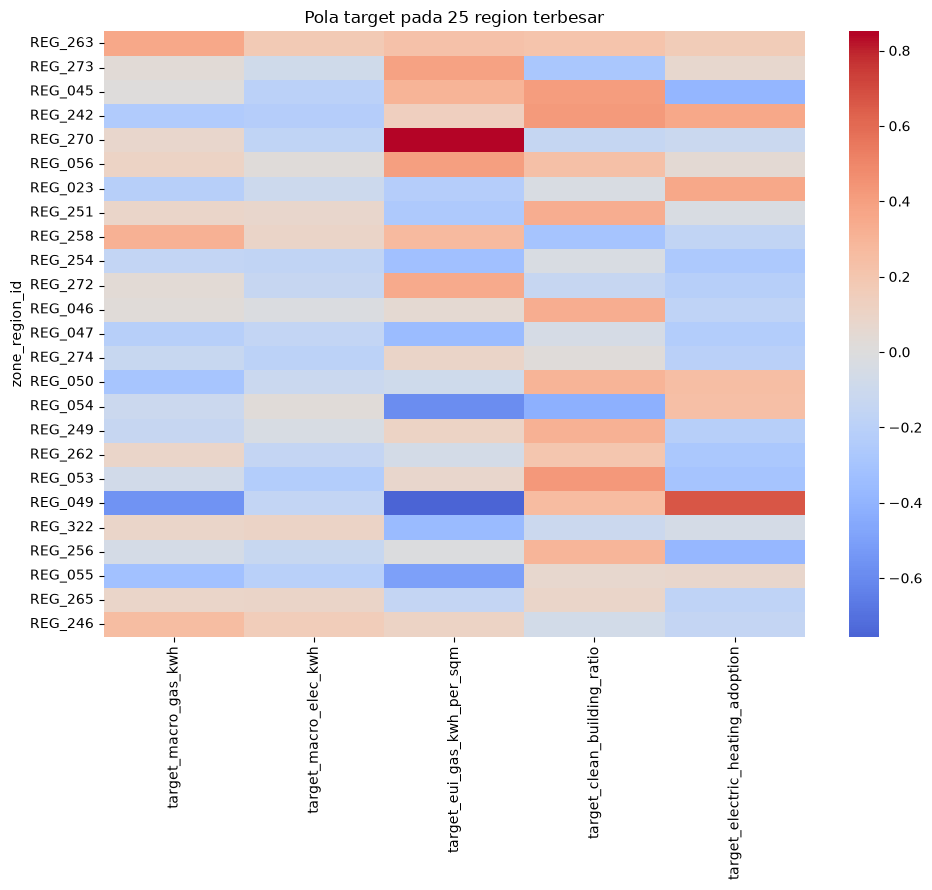

In [33]:
region_means = train.groupby(REGION_COL)[TARGETS].mean()
top_regions = region_counts.head(25).index
scaled_means = (region_means.loc[top_regions] - y_region.mean()) / y_region.std()
plt.figure(figsize=(10, 9))
sns.heatmap(scaled_means, cmap="coolwarm", center=0)
plt.title("Pola target pada 25 region terbesar")
plt.tight_layout()
plt.show()


### 6. Fitur terkait dengan target

Korelasi dipakai untuk memilih hubungan yang perlu ditinjau lebih lanjut, bukan untuk membuang fitur secara otomatis.

In [34]:
num_features = train.select_dtypes(include="number").columns.difference(TARGETS)
unique_counts = train[num_features].nunique(dropna=True)
constant_features = unique_counts[unique_counts <= 1].index.tolist()
varying_features = unique_counts[unique_counts > 1].index.tolist()
corr_table = pd.DataFrame({t: train[varying_features].corrwith(train[t]) for t in TARGETS})
print("Fitur numerik:", len(num_features), "| konstan:", len(constant_features))
print("Fitur konstan:", constant_features)
for t in TARGETS:
    top = corr_table[t].abs().nlargest(7).index
    print(t)
    display(corr_table.loc[top, t].round(3).to_frame("pearson_r"))


Fitur numerik: 199 | konstan: 11
Fitur konstan: ['bld_era_01', 'env_climate_06', 'socio_demog_001', 'socio_demog_004', 'socio_demog_026', 'socio_demog_034', 'socio_demog_039', 'socio_demog_045', 'socio_demog_054', 'socio_demog_060', 'socio_demog_069']
target_macro_gas_kwh


,pearson_r
bld_dim_06,0.899
bld_dim_07,0.899
bld_dim_08,0.897
bld_dim_04,0.881
bld_dim_03,0.881
bld_dim_05,0.878
socio_demog_002,0.874


target_macro_elec_kwh


,pearson_r
bld_dim_12,0.882
bld_dim_06,0.863
bld_dim_08,0.860
bld_dim_07,0.857
bld_dim_03,0.851
bld_dim_05,0.847
bld_dim_04,0.846


target_eui_gas_kwh_per_sqm


,pearson_r
socio_demog_082,-0.194
bld_dim_06,-0.169
bld_dim_08,-0.165
bld_dim_03,-0.164
bld_era_15,0.162
socio_demog_014,0.161
bld_dim_05,-0.160


target_clean_building_ratio


,pearson_r
socio_demog_011,-0.996
bld_dim_13,-0.739
socio_demog_009,-0.735
socio_demog_127,-0.728
socio_demog_003,-0.718
bld_dim_16,-0.709
bld_dim_15,-0.686


target_electric_heating_adoption


,pearson_r
hvac_dist_02,-0.796
socio_demog_035,0.506
socio_demog_057,0.449
socio_demog_051,0.419
socio_demog_061,0.409
socio_demog_027,0.409
socio_demog_055,-0.392


### 6.1 Ringkasan korelasi fitur

Heatmap menampilkan fitur dengan korelasi terbesar untuk masing-masing target.

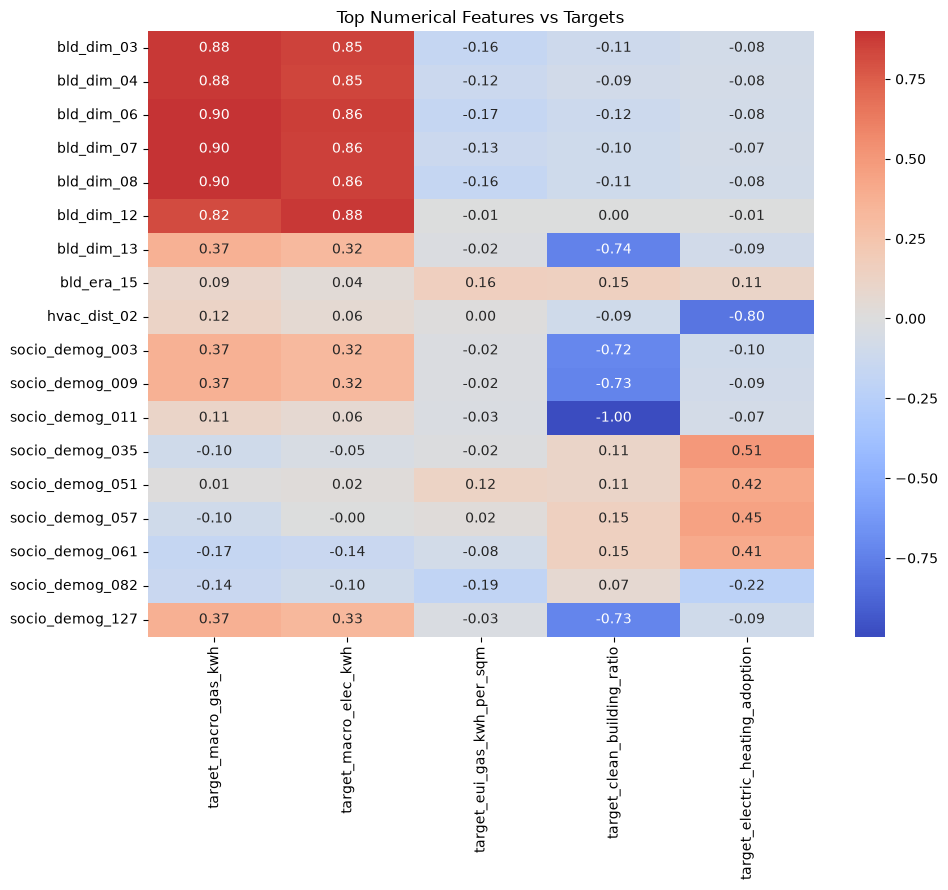

In [35]:
selected = pd.Index([])

for target in TARGET_COLS:
    selected = selected.union(corr_table[target].abs().nlargest(5).index)

plt.figure(figsize=(10, 9))
sns.heatmap(corr_table.loc[selected], annot=True, fmt='.2f',
            cmap='coolwarm', center=0)
plt.title('Top Numerical Features vs Targets')
plt.tight_layout()
plt.show()


### 7. Hubungan nonlinier dan fitur fisik

Gas EUI dianalisis terhadap dimensi bangunan dan era konstruksi sebagai dasar fitur rasio dan interaksi.

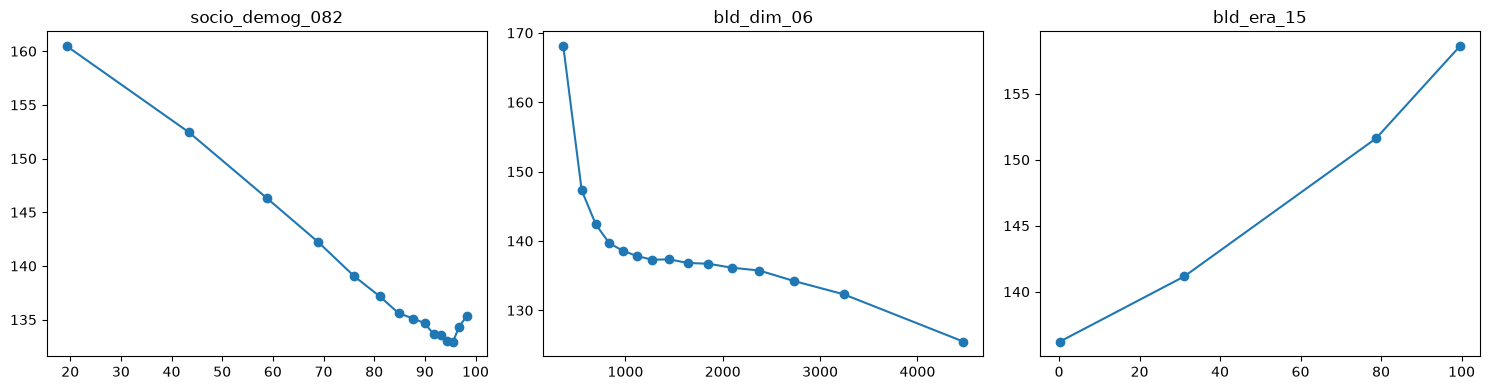

In [36]:
features = ['socio_demog_082', 'bld_dim_06', 'bld_era_15']
target = 'target_eui_gas_kwh_per_sqm'

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, features):
    data = train[[col, target]].dropna().copy()
    data['bin'] = pd.qcut(data[col], q=15, duplicates='drop')
    grouped = data.groupby('bin', observed=True)[[col, target]].mean()
    ax.plot(grouped[col], grouped[target], marker='o')
    ax.set_title(col)

plt.tight_layout()
plt.show()


### 7.1 Interaksi ukuran dan era bangunan

Sel pada heatmap hanya ditampilkan jika terdapat sedikitnya 100 observasi.

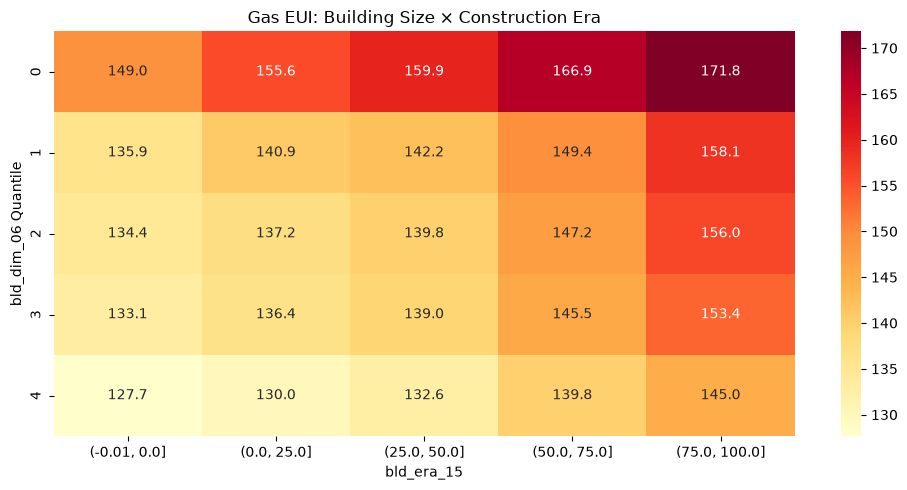

In [37]:
size_bin = pd.qcut(
    train['bld_dim_06'], q=5, labels=False, duplicates='drop'
)

era_bin = pd.cut(
    train['bld_era_15'], bins=[-0.01, 0, 25, 50, 75, 100]
)

grouped = train.groupby(
    [size_bin, era_bin], observed=True
)['target_eui_gas_kwh_per_sqm']

eui_mean = grouped.mean().unstack()
eui_count = grouped.size().unstack(fill_value=0)

plt.figure(figsize=(10, 5))

sns.heatmap(
    eui_mean.mask(eui_count < 100),
    annot=True, fmt='.1f', cmap='YlOrRd'
)

plt.title('Gas EUI: Building Size × Construction Era')
plt.xlabel('bld_era_15')
plt.ylabel('bld_dim_06 Quantile')
plt.tight_layout()
plt.show()


### 8. Perbandingan distribusi train dan test

Uji KS dan proporsi kategori digunakan untuk memeriksa apakah fitur test berbeda jauh dari train.

In [38]:
from scipy.stats import ks_2samp

tr_sample = train.sample(30000, random_state=SEED)
te_sample = test.sample(30000, random_state=SEED)
ks = {col: ks_2samp(tr_sample[col].dropna(), te_sample[col].dropna()).statistic for col in varying_features}
display(pd.Series(ks).sort_values(ascending=False).head(15).round(3))
key_features = ["bld_dim_06", "bld_dim_12", "bld_era_15", "socio_demog_011", "hvac_dist_02"]
display(pd.DataFrame({"train_mean": train[key_features].mean(), "test_mean": test[key_features].mean(), "ks": pd.Series(ks)[key_features]}).round(3))


hvac_dist_03       0.011
socio_demog_123    0.011
socio_demog_025    0.010
socio_demog_097    0.010
socio_demog_051    0.010
env_climate_03     0.010
socio_demog_100    0.010
socio_demog_074    0.009
bld_era_11         0.009
env_climate_02     0.009
env_climate_04     0.009
socio_demog_110    0.009
socio_demog_113    0.009
hvac_dist_09       0.008
socio_demog_024    0.008
dtype: float64

,train_mean,test_mean,ks
bld_dim_06,1711.418,1716.091,0.006
bld_dim_12,22.000,22.073,0.004
bld_era_15,14.106,14.277,0.004
socio_demog_011,9.182,9.175,0.006
hvac_dist_02,82.021,81.988,0.006


### 8.1 Distribusi kategori dan overlap spasial

Memeriksa kategori tersamar serta subzone yang belum ada di train.

In [39]:
for col in ["bld_dim_18", "socio_demog_016"]:
    share = pd.concat([train[col].value_counts(normalize=True).rename("train"),
                       test[col].value_counts(normalize=True).rename("test")], axis=1).fillna(0)
    print(col)
    display((share * 100).round(2))
for col in [REGION_COL, SUBZONE_COL]:
    unseen = ~test[col].isin(train[col])
    print(col, "unseen rows:", unseen.sum(), "|", f"{unseen.mean():.2%}")


bld_dim_18


,train,test
bld_dim_18,,
High (<0%),50.82,50.84
Medium (0-6%),24.09,24.18
Low (6-18%),15.06,14.95
Very Low (>18%),10.03,10.04


socio_demog_016


,train,test
socio_demog_016,,
Urban,87.7,87.73
Rural,12.3,12.27


zone_region_id unseen rows: 0 | 0.00%
subzone_id unseen rows: 14979 | 8.14%


### 9. Kesimpulan EDA

Missing value hanya muncul pada dua fitur dimensi bangunan dan keduanya kosong secara bersamaan. Gas serta listrik memiliki hubungan kuat dengan ukuran bangunan, sedangkan EUI lebih sulit dijelaskan oleh satu fitur. Karakteristik target juga berbeda: clean ratio banyak bernilai 100 dan heating banyak mendekati 0.

Variasi antarkawasan cukup terlihat, terutama pada clean ratio dan EUI, sementara distribusi train dan test relatif serupa. Karena itu model memakai rasio berbasis luas, agregasi region/subzone, dan validasi yang memperhatikan wilayah. Fitur konstan dibuang; nilai kosong tidak diisi secara global agar informasi validasi tetap terjaga.

### 10. Audit hubungan fisik antartarget

Dua hubungan diperiksa pada seluruh data latih sebelum digunakan untuk prediksi atau stacking.

In [40]:
def clean_formula(df):
    """Known candidate: clean buildings / total buildings, reported as a percentage."""
    denom = pd.to_numeric(df["bld_dim_01"], errors="coerce")
    numer = pd.to_numeric(df["bld_dim_02"], errors="coerce")
    with np.errstate(divide="ignore", invalid="ignore"):
        out = 100.0 * numer / denom.where(denom > 0)
    return np.round(out, 2).clip(0, 100).to_numpy(dtype=float)

clean_calc = clean_formula(train)
clean_error = np.abs(clean_calc - train[T_CLEAN].to_numpy(float))
gas_calc = train[T_EUI].to_numpy(float) * train[AREA_COL].to_numpy(float)
gas_error = np.abs(gas_calc - train[T_GAS].to_numpy(float))
print("Clean exact:", np.mean(clean_error < 1e-8), "| max error:", np.nanmax(clean_error))
print("Gas = EUI × luas, max absolute gap:", np.nanmax(gas_error))
print("Gas identity max relative gap:", np.nanmax(gas_error / train[T_GAS].to_numpy(float)))


Clean exact: 1.0 | max error: 0.0
Gas = EUI × luas, max absolute gap: 4.656612873077393e-10
Gas identity max relative gap: 7.749219402669278e-16


### 11. Feature engineering fisik dan spasial

Menggabungkan fitur numerik, rasio per luas, rerata wilayah/subzone, ukuran relatif, dan dua kategori tersamar. Agregasi dihitung hanya dari fitur, tanpa label target.

In [41]:
def make_features(train_df, test_df):
    n_train = len(train_df)
    full = pd.concat([train_df.drop(columns=TARGETS), test_df], ignore_index=True)
    reg, sub = full[REGION_COL], full[SUBZONE_COL]
    numeric_cols = [c for c in full.columns
                    if c not in [ID_COL, REGION_COL, SUBZONE_COL] and pd.api.types.is_numeric_dtype(full[c])]
    F = full[numeric_cols].astype("float32").copy()

    if "bld_dim_18" in full.columns:
        order = {"High (<0%)": 0, "Medium (0-6%)": 1, "Low (6-18%)": 2, "Very Low (>18%)": 3}
        F["bld_dim_18_cat"] = full["bld_dim_18"].map(order).astype("float32")
    if "socio_demog_016" in full.columns:
        rural_urban = {"Rural": 0, "Urban": 1}
        F["socio_demog_016_cat"] = full["socio_demog_016"].map(rural_urban).astype("float32")

    live = [c for c in numeric_cols if F[c].nunique(dropna=True) > 1]
    ratio_cols = [c for c in live if c.startswith(("bld_dim_", "socio_demog_")) and c != AREA_COL]
    agg_cols = [c for c in live if c.startswith(("bld_dim_", "env_climate_"))]
    sub_cols = [c for c in live if c.startswith("bld_dim_")]

    area = F[AREA_COL].where(F[AREA_COL] > 0) if AREA_COL in F.columns else pd.Series(np.nan, index=F.index)
    ratios_per_area = F[ratio_cols].div(area, axis=0).add_suffix("_per_area")
    reg_mean = F[agg_cols].groupby(reg).transform("mean").add_suffix("_reg_mean") if agg_cols else pd.DataFrame(index=F.index)
    sub_mean = F[sub_cols].groupby(sub).transform("mean").add_suffix("_sub_mean") if sub_cols else pd.DataFrame(index=F.index)

    F["region_code"] = pd.factorize(reg)[0].astype("float32")
    F["region_n"] = reg.map(reg.value_counts()).astype("float32")
    F["subzone_n"] = sub.map(sub.value_counts()).astype("float32")
    if AREA_COL in F.columns:
        reg_area = F[AREA_COL].groupby(reg).transform("mean").where(lambda z: z > 0)
        sub_area_sum = F[AREA_COL].groupby(sub).transform("sum").where(lambda z: z > 0)
        F["area_vs_region_mean"] = F[AREA_COL] / reg_area
        F["area_share_in_subzone"] = F[AREA_COL] / sub_area_sum
        F["area_rank_in_region"] = F[AREA_COL].groupby(reg).rank(pct=True).astype("float32")

    selected_pairs = [("bld_dim_12", "bld_dim_03"), ("bld_dim_03", "bld_dim_12"),
                      ("bld_dim_12", "bld_dim_05"), ("bld_dim_06", "bld_dim_02"),
                      ("bld_dim_08", "bld_dim_02"), ("bld_dim_06", "bld_dim_01"),
                      ("bld_dim_04", "bld_dim_12")]
    for a, b in selected_pairs:
        if a in F.columns and b in F.columns:
            den = F[b].where(F[b] > 0)
            F[f"ratio_{a}_{b}"] = F[a] / den
            F[f"logratio_{a}_{b}"] = np.log1p(F[a].clip(lower=0)) - np.log1p(F[b].clip(lower=0))

    F = pd.concat([F, ratios_per_area, reg_mean, sub_mean], axis=1)
    F = F.replace([np.inf, -np.inf], np.nan)
    
    keep = [c for c in F.columns if F[c].notna().any() and F[c].nunique(dropna=True) > 1]
    F = F.loc[:, keep].astype("float32")
    X_tr = F.iloc[:n_train].reset_index(drop=True)
    X_te = F.iloc[n_train:].reset_index(drop=True)
    del full, F
    gc.collect()
    return X_tr, X_te


### 11.1 Membentuk matriks fitur

Menghapus fitur konstan dan kolom tanpa nilai, sambil mempertahankan NaN untuk XGBoost.

In [42]:
X, X_test = make_features(train, test)
area_med = float(np.nanmedian(np.where(train[AREA_COL].to_numpy(float) > 0,
                                       train[AREA_COL].to_numpy(float), np.nan)))
area_tr = np.where(train[AREA_COL].to_numpy(float) > 0, train[AREA_COL].to_numpy(float), area_med).astype(float)
area_te = np.where(test[AREA_COL].to_numpy(float) > 0, test[AREA_COL].to_numpy(float), area_med).astype(float)
BASE_COLS = [c for c in X.columns if not (c.startswith("socio_demog_") and c.endswith("_per_area"))]
print("Fitur train:", X.shape, "| fitur test:", X_test.shape, "| fitur model:", len(BASE_COLS))


Fitur train: (429303, 457) | fitur test: (183987, 457) | fitur model: 340


### 12. Target encoding tanpa kebocoran label

Encoding region/subzone untuk train dibuat melalui inner OOF. Validasi dan test hanya memakai label dari fold latih.

In [43]:
TE_Y = {
    "gas_pa": train[T_GAS].to_numpy(float) / area_tr,
    "elec_pa": train[T_ELEC].to_numpy(float) / area_tr,
    "eui": train[T_EUI].to_numpy(float),
    "clean": train[T_CLEAN].to_numpy(float),
    "heat": train[T_HEAT].to_numpy(float),
}

TE_GROUPS = {
    "region": (train[REGION_COL].to_numpy(), test[REGION_COL].to_numpy(), 10.0),
    "subzone": (train[SUBZONE_COL].to_numpy(), test[SUBZONE_COL].to_numpy(), 2.0),
}

def _encode(keys_fit, y_fit, keys_apply, prior, smoothing):
    d = pd.DataFrame({"key": keys_fit, "y": y_fit}).groupby("key", dropna=False)["y"].agg(["sum", "count"])
    apply = pd.Series(keys_apply)
    sums = apply.map(d["sum"]).fillna(0.0).to_numpy(float)
    counts = apply.map(d["count"]).fillna(0.0).to_numpy(float)
    return ((sums + prior * smoothing) / (counts + smoothing)).astype("float32")

def build_fold_te(fold_i, tr_idx, va_idx, inner_splits=INNER_TE_SPLITS):
    """Training rows use inner OOF encoding; validation/test use outer-train labels only."""
    tr_out, va_out, te_out = {}, {}, {}
    inner = list(KFold(inner_splits, shuffle=True, random_state=SEED + 101 + fold_i).split(np.arange(len(tr_idx))))
    for group_name, (keys_all, keys_test, smoothing) in TE_GROUPS.items():
        for target_name, y_all in TE_Y.items():
            col = f"te_{group_name}_{target_name}"
            y_outer = y_all[tr_idx]
            prior_outer = float(np.mean(y_outer))
            va_out[col] = _encode(keys_all[tr_idx], y_outer, keys_all[va_idx], prior_outer, smoothing)
            te_out[col] = _encode(keys_all[tr_idx], y_outer, keys_test, prior_outer, smoothing)
            enc_train = np.zeros(len(tr_idx), dtype="float32")
            for a, b in inner:
                
                y_inner = y_all[tr_idx[a]]
                prior_inner = float(np.mean(y_inner))
                enc_train[b] = _encode(keys_all[tr_idx[a]], y_inner, keys_all[tr_idx[b]], prior_inner, smoothing)
            tr_out[col] = enc_train
    return pd.DataFrame(tr_out), pd.DataFrame(va_out), pd.DataFrame(te_out)


### 12.1 Menyiapkan encoding setiap fold

Sepuluh kolom encoding disimpan terpisah untuk setiap fold random CV.

In [44]:
t0 = time.time()
FOLD_TE = [build_fold_te(i, tr_idx, va_idx) for i, (tr_idx, va_idx) in enumerate(folds)]
TE_COLS = list(FOLD_TE[0][0].columns)
print("Fold-safe target encoding:", len(TE_COLS), "fitur |", round(time.time() - t0, 1), "detik")


Fold-safe target encoding: 10 fitur | 53.5 detik


### 12.2 Menyiapkan fitur per fold

Matriks fold berisi fitur dasar dan target encoding yang sesuai dengan bagian train/validasi.

In [45]:
def fold_data(i, need_test=True):
    tr_idx, va_idx = folds[i]
    te_tr, te_va, te_te = FOLD_TE[i]
    Xtr = pd.concat([X.iloc[tr_idx][BASE_COLS].reset_index(drop=True), te_tr.reset_index(drop=True)], axis=1)
    Xva = pd.concat([X.iloc[va_idx][BASE_COLS].reset_index(drop=True), te_va.reset_index(drop=True)], axis=1)
    Xte = None
    if need_test:
        Xte = pd.concat([X_test[BASE_COLS].reset_index(drop=True), te_te.reset_index(drop=True)], axis=1)
    return tr_idx, va_idx, Xtr, Xva, Xte


### 13. Skema validasi

Random KFold digunakan agar hasil model tetap sebanding dengan submission. GroupKFold berdasarkan region disiapkan sebagai audit spasial terpisah.

In [46]:
spatial_folds = list(GroupKFold(n_splits=5).split(train, groups=train[REGION_COL]))
for i, (tr_idx, va_idx) in enumerate(spatial_folds, start=1):
    train_regions = set(train[REGION_COL].iloc[tr_idx])
    valid_regions = set(train[REGION_COL].iloc[va_idx])
    assert train_regions.isdisjoint(valid_regions)
    print(f"Spatial fold {i}: {len(tr_idx)} train, {len(va_idx)} valid, overlap region = 0")


Spatial fold 1: 343586 train, 85717 valid, overlap region = 0
Spatial fold 2: 343459 train, 85844 valid, overlap region = 0
Spatial fold 3: 343398 train, 85905 valid, overlap region = 0
Spatial fold 4: 343388 train, 85915 valid, overlap region = 0
Spatial fold 5: 343381 train, 85922 valid, overlap region = 0


### 14. Parameter model

Memakai konfigurasi XGBoost dan MLP yang digunakan dalam jalur submission terbaik; tuning yang tidak dipakai dihapus.

In [47]:
XGB_BASE = dict(max_depth=8, min_child_weight=5.0, reg_lambda=5.0, reg_alpha=0.0,
                gamma=0.0, colsample_bytree=0.5, subsample=0.8)
TUNED_XGB = {
    T_GAS: dict(XGB_BASE),
    T_ELEC: dict(max_depth=6, min_child_weight=47.9839316,
                 reg_lambda=5.0624741, reg_alpha=0.5, gamma=0.5,
                 colsample_bytree=0.5999126, subsample=0.6261717),
    T_EUI: dict(XGB_BASE),
}
TUNE_SPEC = {T_GAS: True, T_ELEC: True, T_EUI: False}
MLP_HP = {
    T_GAS: dict(width=512, depth=2, dropout=0.1475, in_drop=0.0159, lr=0.001392, wd=0.06723, epochs=20, bs=1024),
    T_ELEC: dict(width=512, depth=3, dropout=0.2028, in_drop=0.0085, lr=0.004398, wd=0.00248, epochs=13, bs=2048),
    T_EUI: dict(width=1024, depth=3, dropout=0.1994, in_drop=0.0109, lr=0.001220, wd=0.000135, epochs=9, bs=1024),
}
XGB_DEV = ({"tree_method": "hist", "device": "cuda"} if HAS_GPU else {"tree_method": "hist"}) if int(xgboost.__version__.split(".")[0]) >= 2 else ({"tree_method": "gpu_hist"} if HAS_GPU else {"tree_method": "hist"})


### 15. Fungsi training XGBoost

Membuat model dengan early stopping, pengaturan seed, dan fallback CPU apabila GPU tidak mendukung.

In [48]:
def _fit_xgb(Xtr, ytr, wtr, Xva, yva, wva, params=None, seed=SEED, n_estimators=2400, lr=0.04):
    params = dict(XGB_BASE if params is None else params)
    common = dict(n_estimators=n_estimators, learning_rate=lr, max_bin=128, n_jobs=-1,
                  random_state=seed, early_stopping_rounds=100, eval_metric="rmse",
                  base_score=float(np.average(ytr, weights=wtr)) if wtr is not None else float(np.mean(ytr)), **params)
    device = dict(XGB_DEV)
    model = XGBRegressor(**common, **device)
    fit_kwargs = dict(sample_weight=wtr, eval_set=[(Xva, yva)], verbose=False)
    if wva is not None:
        fit_kwargs["sample_weight_eval_set"] = [wva]
    try:
        model.fit(Xtr, ytr, **fit_kwargs)
    except Exception:
        
        if "device" not in device and device.get("tree_method") != "gpu_hist":
            raise
        del model
        gc.collect()
        cpu_device = {"tree_method": "hist"}
        model = XGBRegressor(**common, **cpu_device)
        model.fit(Xtr, ytr, **fit_kwargs)
    return model


### 15.1 Target langsung dan per luas

Gas dan listrik dilatih dalam dua bentuk: nilai asli serta nilai yang dinormalisasi dengan luas.

In [49]:
def target_setup(target, per_area):
    y = train[target].to_numpy(dtype=float)
    if per_area:
        
        yf = y / area_tr
        w = area_tr / np.mean(area_tr)
        mult_tr, mult_te = area_tr, area_te
    else:
        yf, w = y.copy(), None
        mult_tr, mult_te = np.ones(len(train)), np.ones(len(test))
    return y, yf, w, mult_tr, mult_te


### 16. Fungsi training MLP

Fitur dinormalisasi menggunakan statistik fold latih, lalu jaringan dilatih dengan pembobotan yang sesuai.

In [50]:
def fit_mlp_predict(Xtr, ytr, wtr, Xva, yva, wva, Xte, hp, seed=SEED):
    if not HAS_TORCH:
        raise RuntimeError("PyTorch unavailable")
    torch.manual_seed(seed)
    np.random.seed(seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    med = Xtr.median(axis=0).fillna(0.0)
    A_tr = Xtr.fillna(med).to_numpy(dtype="float32")
    A_va = Xva.fillna(med).to_numpy(dtype="float32")
    A_te = Xte.fillna(med).to_numpy(dtype="float32")
    mu, sd = A_tr.mean(axis=0), A_tr.std(axis=0) + 1e-6
    A_tr = np.clip((A_tr - mu) / sd, -6, 6).astype("float32")
    A_va = np.clip((A_va - mu) / sd, -6, 6).astype("float32")
    A_te = np.clip((A_te - mu) / sd, -6, 6).astype("float32")

    ym, ys = float(np.mean(ytr)), float(np.std(ytr) + 1e-6)
    y_tr = (np.asarray(ytr, dtype="float32") - ym) / ys
    y_va = (np.asarray(yva, dtype="float32") - ym) / ys
    if wtr is None:
        wt = np.ones(len(ytr), dtype="float32")
        wv = np.ones(len(yva), dtype="float32")
    else:
        wt = np.minimum(np.asarray(wtr, dtype="float32") / np.mean(wtr), 20.0)
        wv = np.minimum(np.asarray(wva, dtype="float32") / np.mean(wtr), 20.0)

    to_t = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
    A_tr_t, A_va_t, A_te_t = to_t(A_tr), to_t(A_va), to_t(A_te)
    y_tr_t, y_va_t, wt_t, wv_t = map(to_t, (y_tr, y_va, wt, wv))
    width, depth = int(hp["width"]), int(hp["depth"])
    layers, din = [], A_tr.shape[1]
    if hp.get("in_drop", 0) > 0:
        layers.append(nn.Dropout(float(hp["in_drop"])))
    for k in range(depth):
        dout = max(64, width // (2 ** k))
        layers += [nn.Linear(din, dout), nn.BatchNorm1d(dout), nn.SiLU(), nn.Dropout(float(hp["dropout"]))]
        din = dout
    net = nn.Sequential(*layers, nn.Linear(din, 1)).to(device)
    bs, epochs = int(hp["bs"]), int(hp["epochs"])
    n = len(A_tr_t)
    steps = max(1, math.ceil(n / bs))
    optimizer = torch.optim.AdamW(net.parameters(), lr=float(hp["lr"]) * 0.67, weight_decay=float(hp["wd"]))
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=float(hp["lr"]), total_steps=epochs * steps)

    def predict(A):
        net.eval(); chunks = []
        with torch.no_grad():
            for start in range(0, len(A), 65536):
                chunks.append(net(A[start:start+65536]).squeeze(1))
        return torch.cat(chunks)

    best_loss, best_state = float("inf"), None
    for epoch in range(epochs):
        net.train()
        perm = torch.randperm(n, device=device)
        for start in range(0, n, bs):
            idx = perm[start:start+bs]
            if len(idx) < 2:
                continue
            loss = (wt_t[idx] * (net(A_tr_t[idx]).squeeze(1) - y_tr_t[idx]) ** 2).mean()
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
        val_loss = float((wv_t * (predict(A_va_t) - y_va_t) ** 2).mean().item())
        if val_loss < best_loss:
            best_loss, best_state = val_loss, copy.deepcopy(net.state_dict())
    if best_state is not None:
        net.load_state_dict(best_state)
    pred_va = predict(A_va_t).cpu().numpy() * ys + ym
    pred_te = predict(A_te_t).cpu().numpy() * ys + ym
    del A_tr_t, A_va_t, A_te_t, net, optimizer, scheduler
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()
    return pred_va, pred_te


### 16.1 Prediksi out-of-fold

Setiap kandidat menghasilkan prediksi validasi OOF dan rerata prediksi test dari lima fold.

In [51]:
def _fit_family(family, Xtr, ytr, wtr, Xva, yva, wva, params=None, seed=SEED):
    if family != "xgb":
        raise ValueError(f"Model tidak tersedia: {family}")
    return _fit_xgb(Xtr, ytr, wtr, Xva, yva, wva, params=params, seed=seed)

def run_cv_candidate(target, family, per_area, label, params=None, mlp_hp=None):
    y, yf, w, multiplier_tr, multiplier_te = target_setup(target, per_area)
    oof = np.zeros(len(train), dtype=float)
    te_pred = np.zeros(len(test), dtype=float)
    t0 = time.time()
    for i in range(len(folds)):
        tr_idx, va_idx, Xtr, Xva, Xte = fold_data(i, need_test=True)
        wtr = None if w is None else w[tr_idx]
        wva = None if w is None else w[va_idx]
        if family == "mlp":
            p_va, p_te = fit_mlp_predict(Xtr, yf[tr_idx], wtr, Xva, yf[va_idx], wva, Xte,
                                         hp=mlp_hp or MLP_HP[target], seed=SEED + i)
        else:
            model = _fit_family(family, Xtr, yf[tr_idx], wtr, Xva, yf[va_idx], wva,
                                params=params, seed=SEED + i)
            p_va, p_te = model.predict(Xva), model.predict(Xte)
            del model
        oof[va_idx] = p_va * multiplier_tr[va_idx]
        te_pred += p_te * multiplier_te / len(folds)
        del Xtr, Xva, Xte
        gc.collect()
        print(f"    {label} fold {i+1}/{len(folds)} ({time.time()-t0:.0f}s)")
    oof, te_pred = clipped(target, oof), clipped(target, te_pred)
    score = nrmse_one(target, y, oof)
    print(f"  {target:36s} {label:22s} OOF NRMSE={score:.5f} ({time.time()-t0:.0f}s)")
    return oof, te_pred, score


### 17. Melatih kandidat model akhir

Hanya kandidat XGBoost dan MLP yang berkontribusi pada stack terbaik yang dijalankan.

In [52]:
CANDS = {T_GAS: {}, T_ELEC: {}, T_EUI: {}}
SPECS = {
    T_GAS: [("direct", False), ("per_area", True)],
    T_ELEC: [("direct", False), ("per_area", True)],
    T_EUI: [("direct", False)],
}
for target, specs in SPECS.items():
    for scale_name, per_area in specs:
        for family in ["xgb", "mlp"]:
            if family == "mlp" and per_area != TUNE_SPEC[target]:
                continue
            label = f"{family}_{scale_name}"
            if family == "xgb":
                params = TUNED_XGB[target] if per_area == TUNE_SPEC[target] else XGB_BASE
                oof, pred_te, score = run_cv_candidate(target, family, per_area, label, params=params)
            else:
                oof, pred_te, score = run_cv_candidate(target, family, per_area, label, mlp_hp=MLP_HP[target])
            CANDS[target][label] = (oof, pred_te)
print("Kandidat model:", {t: list(v) for t, v in CANDS.items()})


    xgb_direct fold 1/5 (171s)
    xgb_direct fold 2/5 (363s)
    xgb_direct fold 3/5 (537s)
    xgb_direct fold 4/5 (729s)
    xgb_direct fold 5/5 (897s)
  target_macro_gas_kwh                 xgb_direct             OOF NRMSE=0.25455 (897s)
    xgb_per_area fold 1/5 (155s)
    xgb_per_area fold 2/5 (332s)
    xgb_per_area fold 3/5 (462s)
    xgb_per_area fold 4/5 (613s)
    xgb_per_area fold 5/5 (755s)
  target_macro_gas_kwh                 xgb_per_area           OOF NRMSE=0.25296 (755s)
    mlp_per_area fold 1/5 (23s)
    mlp_per_area fold 2/5 (42s)
    mlp_per_area fold 3/5 (60s)
    mlp_per_area fold 4/5 (79s)
    mlp_per_area fold 5/5 (98s)
  target_macro_gas_kwh                 mlp_per_area           OOF NRMSE=0.25277 (98s)
    xgb_direct fold 1/5 (83s)
    xgb_direct fold 2/5 (163s)
    xgb_direct fold 3/5 (243s)
    xgb_direct fold 4/5 (339s)
    xgb_direct fold 5/5 (421s)
  target_macro_elec_kwh                xgb_direct             OOF NRMSE=0.32382 (421s)
    xgb_per_area fo

### 18. Stacking tiga target energi

Prediksi gas, listrik, dan EUI digabung dengan non-negative least squares. Bobot untuk OOF dihitung silang antar-fold.

In [53]:
def _score_candidate(target, pair):
    return nrmse_one(target, train[target].to_numpy(float), clipped(target, pair[0]))

def _stack_pool(target):
    pool = dict(CANDS[target])
    
    if target == T_EUI:
        for name, (o, te) in CANDS[T_GAS].items():
            pool[f"gas_view/{name}"] = (o / area_tr, te / area_te)
    elif target == T_GAS:
        for name, (o, te) in CANDS[T_EUI].items():
            pool[f"eui_view/{name}"] = (o * area_tr, te * area_te)
    return pool

STACK_WEIGHTS = {}
STACK_SCORES = {}
for target in [T_GAS, T_ELEC, T_EUI]:
    pool = _stack_pool(target)
    names = list(pool)
    A = np.column_stack([pool[k][0] for k in names]).astype(float) / SIGMAS[target]
    At = np.column_stack([pool[k][1] for k in names]).astype(float) / SIGMAS[target]
    valid_cols = np.isfinite(A).all(axis=0) & np.isfinite(At).all(axis=0)
    A, At = A[:, valid_cols], At[:, valid_cols]
    names = [name for name, keep in zip(names, valid_cols) if keep]
    y_scaled = train[target].to_numpy(float) / SIGMAS[target]

    oof_stack = np.zeros(len(train), dtype=float)
    for tr_idx, va_idx in folds:
        weights, _ = nnls(A[tr_idx], y_scaled[tr_idx])
        oof_stack[va_idx] = A[va_idx] @ weights * SIGMAS[target]
    weights_full, _ = nnls(A, y_scaled)
    te_stack = At @ weights_full * SIGMAS[target]
    oof_stack, te_stack = clipped(target, oof_stack), clipped(target, te_stack)
    CANDS[target]["stack"] = (oof_stack, te_stack)
    STACK_WEIGHTS[target] = dict(zip(names, weights_full))
    STACK_SCORES[target] = nrmse_one(target, train[target], oof_stack)
    print(target, "stack NRMSE:", round(STACK_SCORES[target], 5))
    print("Bobot aktif:", {k: round(v, 3) for k, v in STACK_WEIGHTS[target].items() if v > 0.01})


target_macro_gas_kwh stack NRMSE: 0.24878
Bobot aktif: {'xgb_direct': np.float64(0.207), 'xgb_per_area': np.float64(0.272), 'mlp_per_area': np.float64(0.389), 'eui_view/xgb_direct': np.float64(0.097), 'eui_view/mlp_direct': np.float64(0.036)}
target_macro_elec_kwh stack NRMSE: 0.31836
Bobot aktif: {'xgb_direct': np.float64(0.18), 'xgb_per_area': np.float64(0.298), 'mlp_per_area': np.float64(0.522)}
target_eui_gas_kwh_per_sqm stack NRMSE: 0.65718
Bobot aktif: {'xgb_direct': np.float64(0.127), 'mlp_direct': np.float64(0.098), 'gas_view/xgb_direct': np.float64(0.234), 'gas_view/xgb_per_area': np.float64(0.233), 'gas_view/mlp_per_area': np.float64(0.309)}


### 18.1 Konsistensi gas dan EUI

Identitas gas = EUI × luas dimanfaatkan sebagai tambahan kandidat saat menggabungkan prediksi.

In [54]:
def best_blend(target, a, b, label, n_grid=101):
    ws = np.linspace(0.0, 1.0, n_grid)
    scores = [nrmse_one(target, train[target], clipped(target, w*a[0] + (1-w)*b[0])) for w in ws]
    w = float(ws[int(np.argmin(scores))])
    oof = clipped(target, w*a[0] + (1-w)*b[0])
    te = clipped(target, w*a[1] + (1-w)*b[1])
    return (nrmse_one(target, train[target], oof), oof, te), w

for target, source_target in [(T_GAS, T_EUI), (T_EUI, T_GAS)]:
    own_candidates = CANDS[target]
    own_key = min(own_candidates, key=lambda k: _score_candidate(target, own_candidates[k]))
    src_key = min(CANDS[source_target], key=lambda k: _score_candidate(source_target, CANDS[source_target][k]))
    so, st = CANDS[source_target][src_key]
    cross = (so * area_tr, st * area_te) if target == T_GAS else (so / area_tr, st / area_te)
    own = CANDS[target][own_key]
    blend, weight = best_blend(target, own, cross, "cross_target")
    own_candidates["cross_target_blend"] = blend[1], blend[2]
    print(target, "blend NRMSE:", round(blend[0], 5), "| bobot model utama:", round(weight, 2))


target_macro_gas_kwh blend NRMSE: 0.24878 | bobot model utama: 0.95
target_eui_gas_kwh_per_sqm blend NRMSE: 0.65718 | bobot model utama: 0.84


### 19. Model heating berbasis subzone

Subzone yang pernah muncul memakai nilai heating dari train; subzone baru diprediksi dengan Ridge dan residual XGBoost.

In [55]:
heat = train[T_HEAT].to_numpy(float)
sub_train = train[SUBZONE_COL].to_numpy()
sub_test = test[SUBZONE_COL].to_numpy()

def lookup_mean(keys_fit, y_fit, keys_apply):
    means = pd.DataFrame({"key": keys_fit, "y": y_fit}).groupby("key")["y"].mean()
    return pd.Series(keys_apply).map(means).to_numpy(dtype=float)

sub_feat = [c for c in X.columns
            if c.startswith(("socio_demog_", "hvac_dist_", "env_climate_"))
            and not c.endswith(("_per_area", "_reg_mean", "_sub_mean"))]
if "region_code" in X.columns:
    sub_feat.append("region_code")
sub_feat = list(dict.fromkeys(sub_feat))
HV = [c for c in sub_feat if c.startswith("hvac_dist_")]

def heat_features(M):
    F = M[sub_feat].copy().reset_index(drop=True)
    if HV:
        H = M[HV].astype(float).clip(lower=0).reset_index(drop=True)
        F["hv_min"] = H.min(axis=1)
        F["hv_max"] = H.max(axis=1)
        F["hv_mean"] = H.mean(axis=1)
        F["hv_std"] = H.std(axis=1)
        F["hv_argmin"] = H.to_numpy().argmin(axis=1).astype(float)
        for a, b in itertools.combinations(HV, 2):
            F[f"diff_{a}_{b}"] = H[a] - H[b]
            F[f"logdiff_{a}_{b}"] = np.log1p(H[a]) - np.log1p(H[b])
    return F.replace([np.inf, -np.inf], np.nan).astype("float32")

X_HEAT = heat_features(X)
X_HEAT_TEST = heat_features(X_test)


### 19.1 Model untuk subzone yang belum dikenal

Ridge menangkap pola umum heating, lalu XGBoost mempelajari sisa kesalahannya.

In [56]:
def fit_heat_unknown(Xa, ya, Xb):
    """Ridge trend + XGBoost residuals for unseen subzones."""
    med = Xa.median(axis=0).fillna(0.0)
    sc = StandardScaler()
    A = sc.fit_transform(Xa.fillna(med)).astype("float32")
    B = sc.transform(Xb.fillna(med)).astype("float32")
    ridge = Ridge(alpha=10.0)
    ridge.fit(A, ya)
    r_train = ya - ridge.predict(A)

    rng = np.random.default_rng(SEED)
    order = rng.permutation(len(ya))
    n_val = max(1, int(0.05 * len(ya)))
    val_i, fit_i = order[:n_val], order[n_val:]
    model = _fit_xgb(Xa.iloc[fit_i], r_train[fit_i], None,
                     Xa.iloc[val_i], r_train[val_i], None,
                     params=dict(max_depth=6, min_child_weight=15, reg_lambda=20,
                                 reg_alpha=0.0, gamma=0.5, colsample_bytree=0.5, subsample=0.8),
                     n_estimators=1800, lr=0.04)
    return ridge.predict(B) + model.predict(Xb)


### 19.2 Heating OOF dan prediksi test

Lookup dibuat dari label dalam fold latih; label validasi tidak digunakan saat menghitung prediksi OOF.

In [57]:
heat_oof = np.zeros(len(train), dtype=float)
heat_oof_seen = np.zeros(len(train), dtype=bool)
t0 = time.time()
for fold_i, (tr_idx, va_idx) in enumerate(folds):
    train_keys = sub_train[tr_idx]
    first_mask = ~pd.Series(train_keys).duplicated().to_numpy()
    u_idx = tr_idx[first_mask]
    y_unique = heat[u_idx]
    lookup = lookup_mean(sub_train[tr_idx], heat[tr_idx], sub_train[va_idx])
    unseen_mask = ~np.isfinite(lookup)
    fold_pred = lookup.copy()
    if unseen_mask.any():
        fold_pred[unseen_mask] = fit_heat_unknown(X_HEAT.iloc[u_idx].reset_index(drop=True), y_unique,
                                                  X_HEAT.iloc[va_idx[unseen_mask]].reset_index(drop=True))
    heat_oof[va_idx] = np.clip(fold_pred, 0, 100)
    heat_oof_seen[va_idx] = ~unseen_mask
    print(f"Heating fold {fold_i + 1}/{len(folds)}, seen subzone: {np.mean(~unseen_mask):.3f}")

lookup_test = lookup_mean(sub_train, heat, sub_test)
heat_test = lookup_test.copy()
unseen_test_mask = ~np.isfinite(lookup_test)
if unseen_test_mask.any():
    first_global = ~pd.Series(sub_train).duplicated().to_numpy()
    u_global = np.flatnonzero(first_global)
    heat_test[unseen_test_mask] = fit_heat_unknown(X_HEAT.iloc[u_global].reset_index(drop=True), heat[u_global],
                                                   X_HEAT_TEST.iloc[unseen_test_mask].reset_index(drop=True))
heat_oof, heat_test = clipped(T_HEAT, heat_oof), clipped(T_HEAT, heat_test)
CANDS[T_HEAT] = {"subzone_lookup_plus_ridge_xgb": (heat_oof, heat_test)}
print("Heating OOF NRMSE:", round(nrmse_one(T_HEAT, heat, heat_oof), 5))
print("Subzone seen pada validasi:", round(heat_oof_seen.mean(), 4))
print("Subzone seen pada test:", round(np.isfinite(lookup_test).mean(), 4))


Heating fold 1/5, seen subzone: 0.870
Heating fold 2/5, seen subzone: 0.869
Heating fold 3/5, seen subzone: 0.869
Heating fold 4/5, seen subzone: 0.869
Heating fold 5/5, seen subzone: 0.868
Heating OOF NRMSE: 0.05072
Subzone seen pada validasi: 0.8692
Subzone seen pada test: 0.9186


### 20. Audit validasi spasial

GroupKFold memisahkan seluruh region antara train dan validasi. Audit memakai model XGBoost dasar tanpa target encoding dan estimator heating; skornya tidak dibandingkan langsung dengan OOF ensemble.

In [58]:
RUN_SPATIAL_AUDIT = True
spatial_predictions = {t: np.full(len(train), np.nan) for t in TARGETS}

if RUN_SPATIAL_AUDIT:
    for fold_i, (tr_idx, va_idx) in enumerate(spatial_folds):
        Xtr = X.iloc[tr_idx][BASE_COLS]
        Xva = X.iloc[va_idx][BASE_COLS]
        for target, per_area in [(T_GAS, True), (T_ELEC, True), (T_EUI, False)]:
            y_raw, y_fit, weights, multiplier, _ = target_setup(target, per_area)
            params = TUNED_XGB[target] if per_area == TUNE_SPEC[target] else XGB_BASE
            model = _fit_xgb(Xtr, y_fit[tr_idx], None if weights is None else weights[tr_idx],
                             Xva, y_fit[va_idx], None if weights is None else weights[va_idx],
                             params=params, seed=SEED + 500 + fold_i)
            spatial_predictions[target][va_idx] = clipped(target, model.predict(Xva) * multiplier[va_idx])
            del model

        train_keys = sub_train[tr_idx]
        unique_idx = tr_idx[~pd.Series(train_keys).duplicated().to_numpy()]
        looked = lookup_mean(sub_train[tr_idx], heat[tr_idx], sub_train[va_idx]).copy()
        unseen_mask = ~np.isfinite(looked)
        if unseen_mask.any():
            looked[unseen_mask] = fit_heat_unknown(
                X_HEAT.iloc[unique_idx].reset_index(drop=True), heat[unique_idx],
                X_HEAT.iloc[va_idx[unseen_mask]].reset_index(drop=True))
        spatial_predictions[T_HEAT][va_idx] = clipped(T_HEAT, looked)
        spatial_predictions[T_CLEAN][va_idx] = clipped(T_CLEAN, clean_formula(train.iloc[va_idx]))
        print(f"Spatial fold {fold_i + 1}/5 selesai")
        gc.collect()

    spatial_scores = pd.Series({t: nrmse_one(t, train[t], spatial_predictions[t]) for t in TARGETS})
    display(spatial_scores.to_frame("Spatial NRMSE").round(5))
    print("Spatial GroupKFold baseline:", round(spatial_scores.mean(), 5))


Spatial fold 1/5 selesai
Spatial fold 2/5 selesai
Spatial fold 3/5 selesai
Spatial fold 4/5 selesai
Spatial fold 5/5 selesai


,Spatial NRMSE
target_macro_gas_kwh,0.26881
target_macro_elec_kwh,0.32858
target_eui_gas_kwh_per_sqm,0.69106
target_clean_building_ratio,0.00000
target_electric_heating_adoption,0.11850


Spatial GroupKFold baseline: 0.28139


### 21. Formula clean building

Formula hanya dipakai jika cocok pada seluruh baris train dan terdefinisi pada seluruh test.

In [59]:
clean_formula_train = clean_formula(train)
clean_formula_test = clean_formula(test)
clean_formula_matches = np.isfinite(clean_formula_train) & (
    np.abs(clean_formula_train - train[T_CLEAN].to_numpy(float)) <= 1e-8)
clean_formula_is_exact = bool(clean_formula_matches.all() and np.isfinite(clean_formula_test).all())
if clean_formula_is_exact:
    CANDS[T_CLEAN] = {
        "exact_formula_100_bld02_over_bld01": (
            clipped(T_CLEAN, clean_formula_train), clipped(T_CLEAN, clean_formula_test))}
    print("Formula clean cocok pada seluruh baris train.")
else:
    raise ValueError("Formula clean tidak cocok. Periksa versi data sebelum membuat submission.")


Formula clean cocok pada seluruh baris train.


### 22. Evaluasi akhir lima target

Memilih kandidat dengan NRMSE pengembangan terendah. Angka OOF adalah estimasi seleksi model, bukan hasil nested CV independen.

In [60]:
FINAL_OOF, FINAL_TEST, FINAL_ROWS = {}, {}, []
for target in TARGETS:
    candidate_scores = {name: _score_candidate(target, pair) for name, pair in CANDS[target].items()}
    best_name = min(candidate_scores, key=candidate_scores.get)
    best_oof, best_test = CANDS[target][best_name]
    FINAL_OOF[target] = clipped(target, best_oof)
    FINAL_TEST[target] = clipped(target, best_test)
    FINAL_ROWS.append({"target": target, "best_candidate": best_name, "OOF_NRMSE": candidate_scores[best_name]})

score_table = pd.DataFrame(FINAL_ROWS)
display(score_table.round(5))
OOF_SCORE = float(score_table["OOF_NRMSE"].mean())
print("Overall Column-Wise NRMSE (OOF):", round(OOF_SCORE, 6))


,target,best_candidate,OOF_NRMSE
0,target_macro_gas_kwh,cross_target_blend,0.24878
1,target_macro_elec_kwh,stack,0.31836
2,target_eui_gas_kwh_per_sqm,cross_target_blend,0.65718
3,target_clean_building_ratio,exact_formula_100_bld02_over_bld01,0.00000
4,target_electric_heating_adoption,subzone_lookup_plus_ridge_xgb,0.05072


Overall Column-Wise NRMSE (OOF): 0.255007


### 23. Menyimpan submission

Menghasilkan CSV sesuai urutan ID test dan memeriksa nilai kosong serta batas persentase.

In [61]:
submission = pd.DataFrame({ID_COL: test[ID_COL].values})
for target in TARGETS:
    submission[target] = FINAL_TEST[target]
assert submission.shape == (len(test), 6)
assert submission[ID_COL].equals(test[ID_COL])
assert np.isfinite(submission[TARGETS].to_numpy(dtype=float)).all()
assert submission[[T_CLEAN, T_HEAT]].ge(0).all().all()
assert submission[[T_CLEAN, T_HEAT]].le(100).all().all()
submission.to_csv(SUBMISSION_PATH, index=False)
print("Saved:", SUBMISSION_PATH, "| shape:", submission.shape)
display(submission.head())


Saved: submission_dicefest_gabungan.csv | shape: (183987, 6)


,id,target_macro_gas_kwh,target_macro_elec_kwh,target_eui_gas_kwh_per_sqm,target_clean_building_ratio,target_electric_heating_adoption
0,ID_429304,572718.939091,113492.835694,132.496846,86.84,14.285714
1,ID_429305,164913.633415,40484.418914,119.048227,100.00,8.235294
2,ID_429306,126629.867067,33212.911943,151.549436,92.31,7.500000
3,ID_429307,237445.838833,85751.100448,121.974303,81.82,2.068966
4,ID_429308,157743.873422,45768.303569,109.197315,100.00,0.000000


In [62]:
# Hitung feature importance XGBoost untuk tiga target utama

importance_results = {}

for target, per_area in [(T_GAS, True), (T_ELEC, True), (T_EUI, False)]:
    tr_idx, va_idx, Xtr, Xva, _ = fold_data(0, need_test=False)
    _, y, w, _, _ = target_setup(target, per_area)

    model = _fit_xgb(
        Xtr, y[tr_idx], None if w is None else w[tr_idx],
        Xva, y[va_idx], None if w is None else w[va_idx],
        params=TUNED_XGB[target]
    )

    importance_results[target] = pd.Series(
        model.feature_importances_,
        index=Xtr.columns
    ).nlargest(15)

    print(target, "selesai")

target_macro_gas_kwh selesai
target_macro_elec_kwh selesai
target_eui_gas_kwh_per_sqm selesai


### 24. SHAP (SHapley Additive exPlanations)

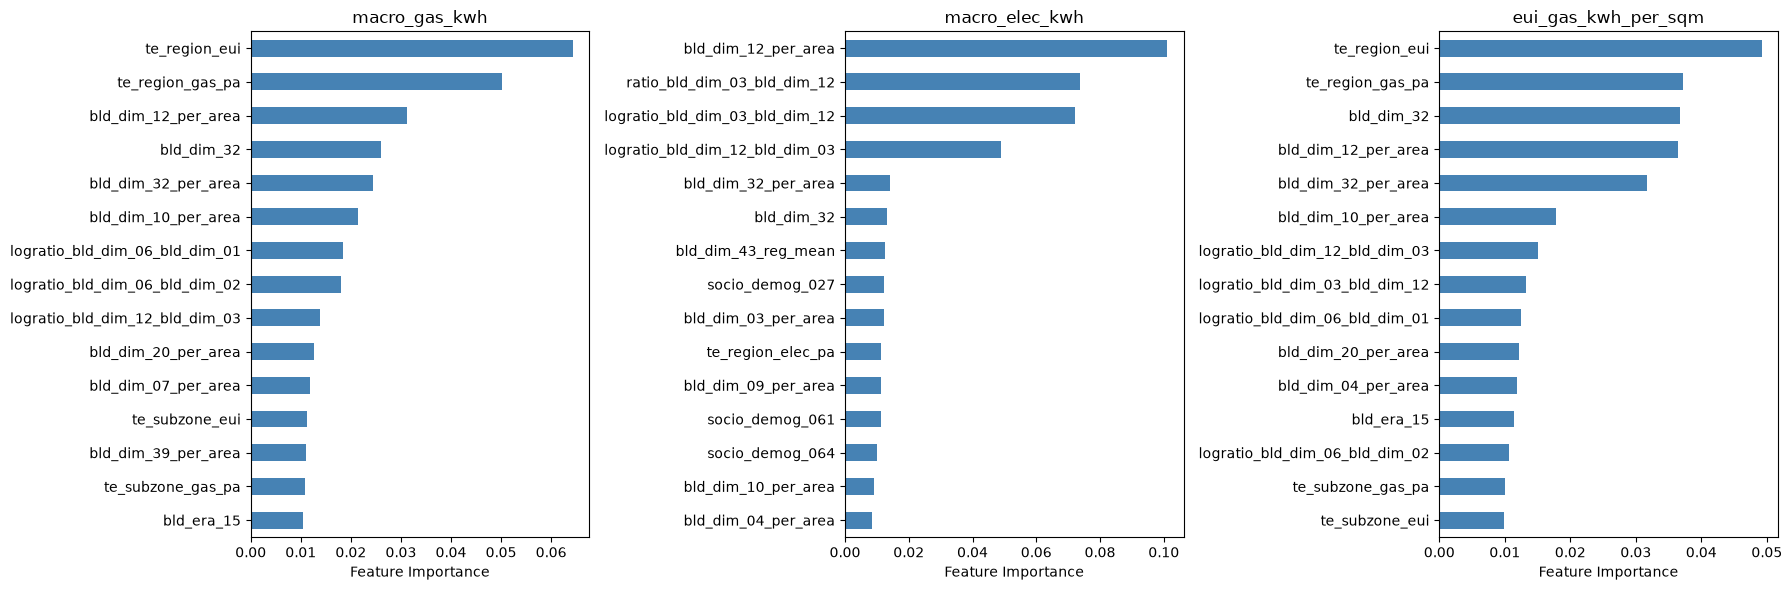

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (target, importance) in zip(axes, importance_results.items()):
    importance.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(target.replace("target_", ""))
    ax.set_xlabel("Feature Importance")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

### Catatan hasil

Model akhir dilatih sebagai lima keluaran melalui strategi khusus per target: XGBoost/MLP dan stacking untuk gas, listrik, EUI; formula untuk clean building; serta lookup dan model residual untuk heating. Hasil OOF dari notebook adalah **0,255007**.

Validasi spasial pada bagian 20 memakai baseline XGBoost terpisah, bukan model ensemble final. Semua target dinilai dengan sigma resmi, tanpa data eksternal atau API prediksi berbayar.